In [4]:
from pathlib import Path
from pprint import pprint

import pandas as pd
from presp.prescriptor import NNPrescriptorFactory
import matplotlib.pyplot as plt
import yaml

from constraint.evaluator import ConstraintEvaluator
from constraint.prescriptor import ConstraintPrescriptor
from experiments.experiment_utils import NNExperimenter
from evolution.utils import process_config
from enroadspy import load_input_specs, name_to_id, id_to_name
from enroadspy.generate_url import open_browser

In [5]:
RESULTS_DIR = Path("results/constraint-dummy")
with open(RESULTS_DIR / "config.yml", "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

pprint(config)

config = process_config(config)

input_specs = load_input_specs()

{'actions': ['Carbon tax initial target'],
 'batch_size': 64,
 'context': ['Carbon tax initial target'],
 'device': 'mps',
 'evolution_params': {'mutation_factor': 0.1,
                      'mutation_rate': 0.1,
                      'n_elites': 0,
                      'n_generations': 10,
                      'population_size': 10,
                      'remove_population_pct': 0.0,
                      'save_path': 'results/constraint-dummy'},
 'model_params': [{'in_features': 2, 'out_features': 64, 'type': 'linear'},
                  {'type': 'tanh'},
                  {'in_features': 64, 'out_features': 1, 'type': 'linear'},
                  {'type': 'sigmoid'}],
 'n_jobs': 1,
 'outcomes': {'Max cost of energy': True, 'Temperature change from 1850': True}}


In [6]:
results_df = pd.read_csv(RESULTS_DIR / "results.csv")
GENS = results_df["gen"].max()
gen_df = results_df[results_df["gen"] == GENS]
gen_df

,gen,cand_id,parents,cv,rank,distance,Temperature change from 1850,Max cost of energy
90,10,1_0,NaN,0,1,inf,2.841182,31.15910
91,10,1_6,NaN,0,1,inf,2.914752,30.29280
92,10,10_6,"['1_0', '3_8']",0,1,inf,2.841182,31.15910
93,10,10_9,"['9_8', '9_5']",0,1,inf,2.914752,30.29280
94,10,10_8,"['1_2', '1_2']",0,1,0.484800,2.897231,30.50422
95,10,8_3,"['7_4', '7_1']",0,1,0.482196,2.848035,31.07611
96,10,5_5,"['2_4', '2_4']",0,1,0.416704,2.884606,30.67513
97,10,9_9,"['7_8', '7_8']",0,1,0.366296,2.888975,30.63393
98,10,10_4,"['3_8', '9_5']",0,1,0.347727,2.858305,30.94300
99,10,10_1,"['7_1', '7_1']",0,1,0.345104,2.872024,30.79532


In [7]:
factory = NNPrescriptorFactory(ConstraintPrescriptor,
                               model_params=config["model_params"],
                               actions=config["actions"],
                               context=config["context"],
                               device=config["device"])

evaluator = ConstraintEvaluator(config["context"],
                                config["actions"],
                                config["outcomes"],
                                config["n_jobs"],
                                config["batch_size"],
                                config["device"])

population = factory.load_population(RESULTS_DIR / "population")

make: `enroads' is up to date.


In [8]:
actions_dicts = evaluator.prescribe_actions(population["1_0"])
actions_dicts

[{39: 24.850440979003906},
 {39: 49.83881759643555},
 {39: 74.82608032226562},
 {39: 99.81208801269531},
 {39: 124.79669189453125},
 {39: 149.77969360351562},
 {39: 174.76087951660156},
 {39: 199.7400360107422},
 {39: 224.7168426513672},
 {39: 249.6910400390625}]

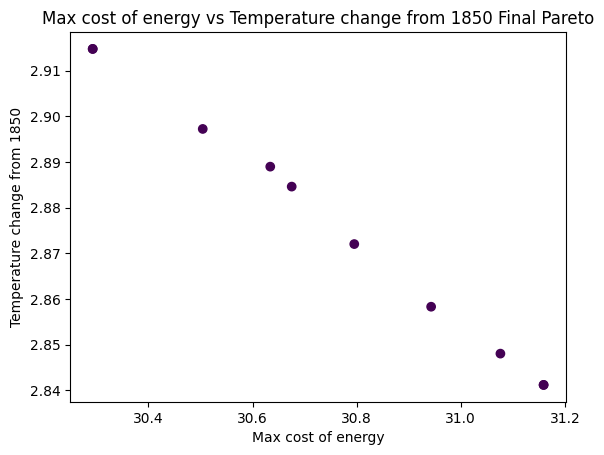

In [9]:
def plot_two_objective(outcome1: str, outcome2: str, results_df: pd.DataFrame, gens: list[int], pareto=True):

    gen_dfs = []
    for gen in gens:
        gen_df = results_df[results_df["gen"] == gen]
        gen_df = gen_df[gen_df["rank"] == 1] if pareto else gen_df
        gen_df["color"] = gen
        gen_dfs.append(gen_df)
    
    total_gen_df = pd.concat(gen_dfs)
    cmap = "viridis_r" if len(gens) != 1 else "viridis"
    fig, ax = plt.subplots()
    scatter = ax.scatter(total_gen_df[outcome1], total_gen_df[outcome2], c=total_gen_df["color"], cmap=cmap)

    title = f"{outcome1} vs {outcome2} Final Pareto"

    if len(gens) != 1:
        cbar = fig.colorbar(scatter)
        cbar.set_label("Generation", rotation=270, labelpad=15)
        title = f"{outcome1} vs {outcome2} over Evolution"
    
    ax.set_title(title)

    ax.set_ylabel(outcome2)
    ax.set_xlabel(outcome1)
    plt.show()

plot_two_objective("Max cost of energy", "Temperature change from 1850", results_df, gens=[10], pareto=True)

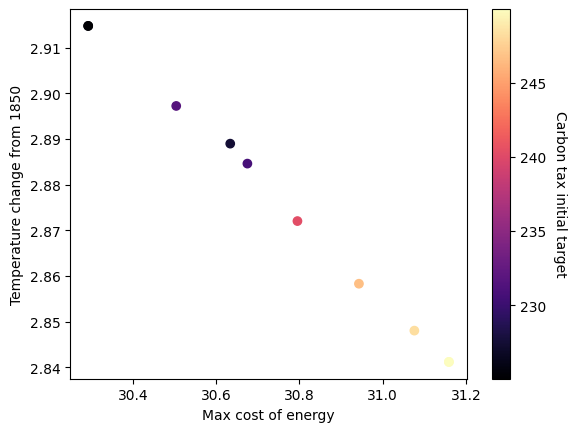

In [14]:
def color_pareto_by_action(action: str, outcome_1: str, outcome_2: str, gen: int, results_df: pd.DataFrame):
    pareto_df = results_df[(results_df["gen"] == gen) & (results_df["rank"] == 1)].copy()

    action = name_to_id(action, input_specs)

    action_vals = []
    for cand_id in pareto_df["cand_id"]:
        context_actions_dicts = evaluator.prescribe_actions(population[cand_id])
        avg_actions_dict = {}
        for context_actions_dict in context_actions_dicts:
            for k, v in context_actions_dict.items():
                avg_actions_dict[k] = avg_actions_dict.get(k, 0) + v
        for k in avg_actions_dict:
            avg_actions_dict[k] /= len(context_actions_dicts)
        action_vals.append(context_actions_dict[action])
    
    pareto_df["action"] = action_vals

    fig, ax = plt.subplots()
    min_val = min(action_vals)
    max_val = max(action_vals)
    if min_val < 0 and max_val > 0:
        cmap_params = {"cmap": "PiYG", "vmin": min(min_val, -max_val), "vmax": max(-min_val, max_val)}
    else:
        cmap_params = {"cmap": "magma"}
    scatter = ax.scatter(pareto_df[outcome_1], pareto_df[outcome_2], c=pareto_df["action"], **cmap_params)
    ax.set_xlabel(outcome_1)
    ax.set_ylabel(outcome_2)
    cbar = fig.colorbar(scatter)
    cbar.set_label(id_to_name(action, load_input_specs()), rotation=270, labelpad=15)
    plt.show()

color_pareto_by_action("Carbon tax initial target", "Max cost of energy", "Temperature change from 1850", GENS, results_df)